## DBSCAN - IRIS

In [40]:
from sklearn.datasets import load_iris
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [41]:
iris = load_iris()

X = iris.data
y = iris.target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

<Axes: >

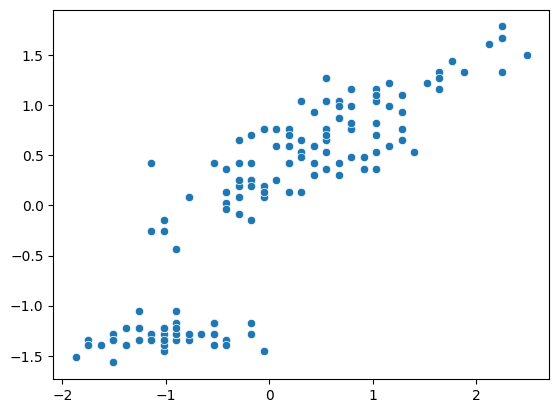

In [42]:
sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:, 2])

<Axes: >

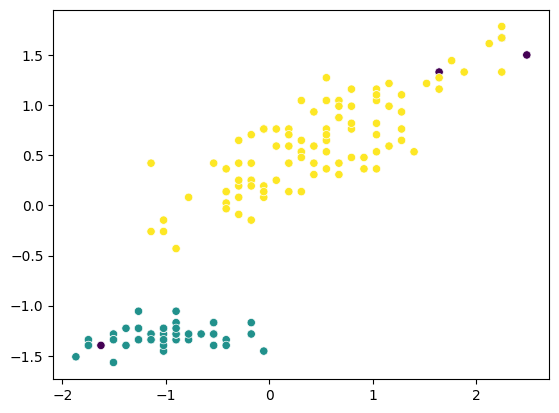

In [43]:
from sklearn.cluster import DBSCAN

dbs = DBSCAN(
    eps=0.8,
    min_samples=5
)

labels = dbs.fit_predict(X_scaled)

sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:, 2], c=labels)

## DBSCAN VS KMEANS
- Non-linear datasets

In [44]:
from sklearn.datasets import make_moons

X, y = make_moons(
    n_samples=300,
    noise=0.05,
    random_state=42
)

X_scaled = scaler.fit_transform(X)

<Axes: >

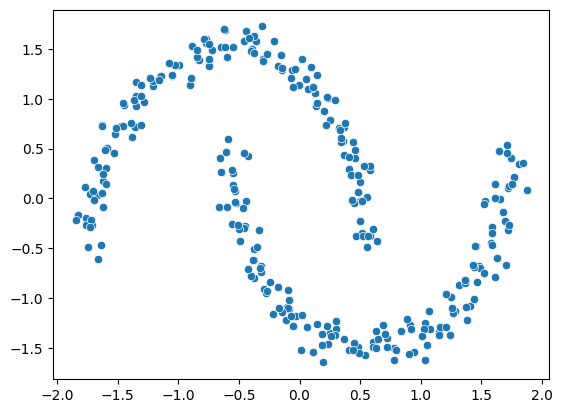

In [45]:
sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:, 1])

### KMEANS

In [46]:
from sklearn.cluster import KMeans
from kneed import KneeLocator
from sklearn.metrics import silhouette_score


wcss = []
ss = []
for k in range(2, 21):
    kmeans = KMeans(n_clusters=k)
    labels = kmeans.fit_predict(X_scaled)
    wcss.append(kmeans.inertia_)
    ss.append(silhouette_score(X_scaled, labels))

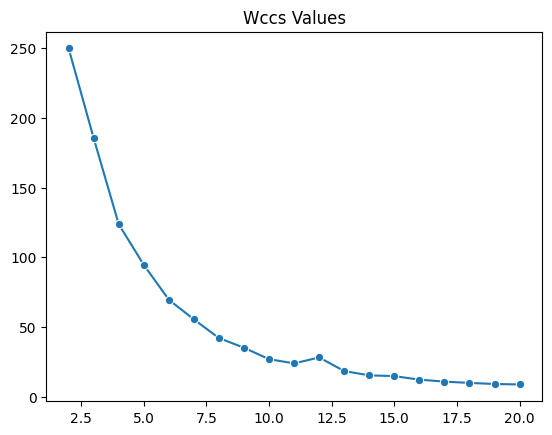

In [47]:
sns.lineplot(x=range(2, 21), y=wcss, marker="o")
plt.title("Wccs Values")
plt.show()

In [48]:
knee = KneeLocator(range(2 , 21), y=wcss)
knee.elbow

np.int64(2)

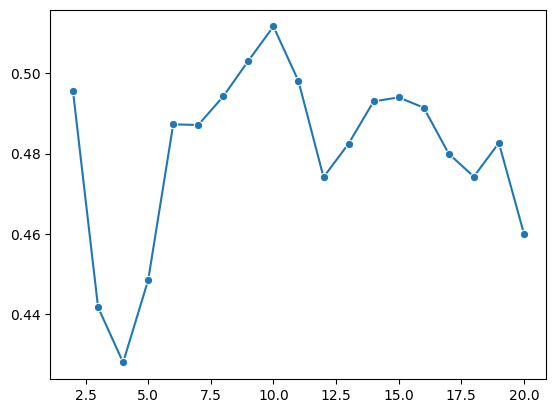

In [51]:
sns.lineplot(x=range(2 , 21), y=ss, marker="o")
plt.show()

In [58]:
kmeans = KMeans(n_clusters=2)
labels = kmeans.fit_predict(X_scaled)

<Axes: >

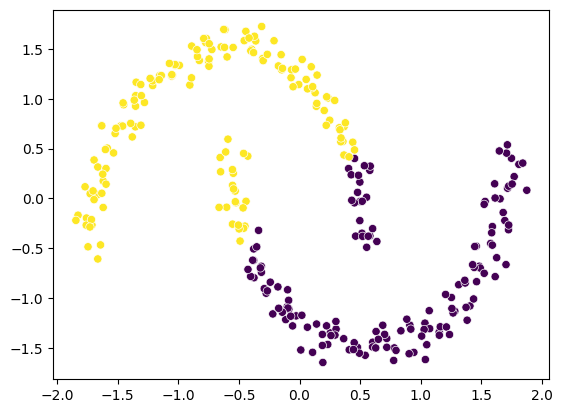

In [59]:
sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:, 1], c=labels)

<Axes: >

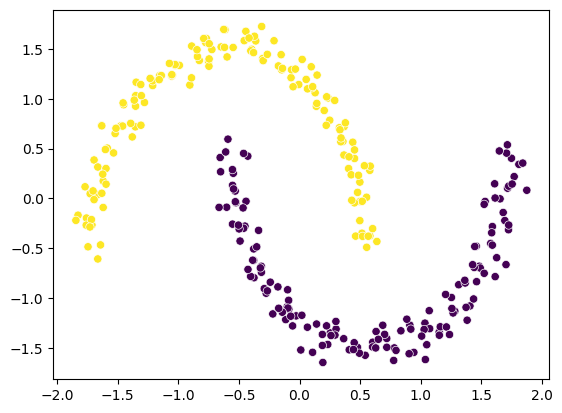

In [62]:
dbs = DBSCAN(
    eps=0.5,
    min_samples=5
)

labels = dbs.fit_predict(X_scaled)

sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:, 1], c=labels)